In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime

# 1. Data collection

In [2]:
now = datetime.now()
start = datetime(now.year-10, now.month, now.day)
end = now
ticker = 'AAPL'
df = yf.download(ticker, start, end)
df

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2016-10-11,26.596138,27.142696,26.573268,26.916296,256164000
2016-10-12,26.833975,26.980335,26.699051,26.836262,150347200
2016-10-13,26.751646,26.856841,26.463502,26.708195,140769600
2016-10-14,26.900291,27.023782,26.785949,26.957463,142608800
2016-10-17,26.882004,26.948321,26.705915,26.831693,94499600
...,...,...,...,...,...
2026-10-05,332.890015,336.209991,331.649994,332.820007,34400900
2026-10-06,333.630005,334.380005,330.619995,332.279999,30449000


In [3]:
df.tail()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2026-10-05,332.890015,336.209991,331.649994,332.820007,34400900
2026-10-06,333.630005,334.380005,330.619995,332.279999,30449000
2026-10-07,336.670013,338.670013,332.779999,336.959991,34147900
2026-10-08,340.420013,341.570007,335.899994,336.820007,35332400
2026-10-09,336.640015,338.609985,330.700012,331.700012,37855000


# 2. Data Exploration and Visualization

In [4]:
type(df)

pandas.DataFrame

In [5]:
df.shape


(2513, 5)

In [6]:
df.isna().sum()

Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64

In [7]:
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
count,2513.000000,2513.000000,2513.000000,2513.000000,2.513000e+03
mean,134.690771,136.038334,133.204250,134.552213,9.312285e+07
std,82.273805,83.069250,81.380933,82.165034,5.361768e+07
min,24.298477,24.751295,23.923806,24.496151,1.791060e+07
25%,48.789276,49.213927,48.372598,48.737488,5.441290e+07
50%,138.752594,140.545037,137.000183,138.920373,8.102960e+07
75%,189.255951,191.034810,187.889306,189.104541,1.135284e+08
max,341.070007,345.339996,338.750000,341.079987,4.479400e+08


In [8]:
df.dtypes

Price   Ticker
Close   AAPL      float64
High    AAPL      float64
Low     AAPL      float64
Open    AAPL      float64
Volume  AAPL        int64
dtype: object

In [9]:
df = df.reset_index()

In [10]:
df.head()

Price,Date,Close,High,Low,Open,Volume
Ticker,,AAPL,AAPL,AAPL,AAPL,AAPL
0,2016-10-11,26.596138,27.142696,26.573268,26.916296,256164000
1,2016-10-12,26.833975,26.980335,26.699051,26.836262,150347200
2,2016-10-13,26.751646,26.856841,26.463502,26.708195,140769600
3,2016-10-14,26.900291,27.023782,26.785949,26.957463,142608800
4,2016-10-17,26.882004,26.948321,26.705915,26.831693,94499600


In [11]:
df.shape

(2513, 6)

Text(0, 0.5, 'Close Price')

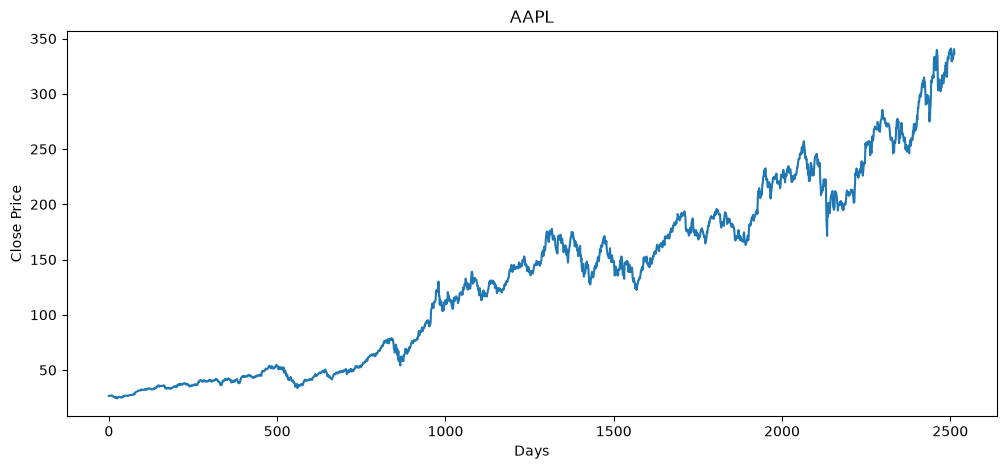

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(df.Close)
plt.title(ticker)
plt.xlabel("Days")
plt.ylabel("Close Price")

# 3. Feature Engineering

### 100 days moving average

In [13]:
df['MA_100'] = df.Close.rolling(100).mean()

In [14]:
df.head(103)

Price,Date,Close,High,Low,Open,Volume,MA_100
Ticker,,AAPL,AAPL,AAPL,AAPL,AAPL,
0,2016-10-11,26.596138,27.142696,26.573268,26.916296,256164000,NaN
1,2016-10-12,26.833975,26.980335,26.699051,26.836262,150347200,NaN
2,2016-10-13,26.751646,26.856841,26.463502,26.708195,140769600,NaN
3,2016-10-14,26.900291,27.023782,26.785949,26.957463,142608800,NaN
4,2016-10-17,26.882004,26.948321,26.705915,26.831693,94499600,NaN
...,...,...,...,...,...,...,...
98,2017-03-03,32.269089,32.280632,31.994369,32.038232,84432400,NaN
99,2017-03-06,32.167515,32.266785,31.996683,32.174440,87000000,27.471450
100,2017-03-07,32.209068,32.315260,32.040541,32.102873,69785200,27.527579


Text(0, 0.5, 'Close Price')

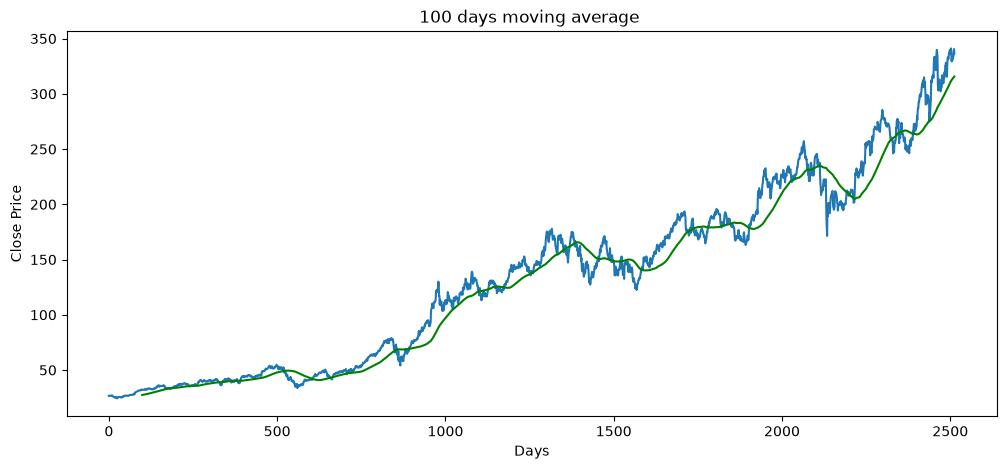

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(df.Close)
plt.plot(df['MA_100'], 'g')
plt.title('100 days moving average ')
plt.xlabel("Days")
plt.ylabel("Close Price")

### 200 days moving average

In [16]:
df['MA_200'] = df.Close.rolling(200).mean()

In [17]:
df.head(203)

Price,Date,Close,High,Low,Open,Volume,MA_100,MA_200
Ticker,,AAPL,AAPL,AAPL,AAPL,AAPL,,
0,2016-10-11,26.596138,27.142696,26.573268,26.916296,256164000,NaN,NaN
1,2016-10-12,26.833975,26.980335,26.699051,26.836262,150347200,NaN,NaN
2,2016-10-13,26.751646,26.856841,26.463502,26.708195,140769600,NaN,NaN
3,2016-10-14,26.900291,27.023782,26.785949,26.957463,142608800,NaN,NaN
4,2016-10-17,26.882004,26.948321,26.705915,26.831693,94499600,NaN,NaN
...,...,...,...,...,...,...,...,...
198,2017-07-26,35.573448,35.682395,35.480722,35.547949,63124000,33.893698,NaN
199,2017-07-27,34.901211,35.696319,34.145514,35.640683,129905200,33.921035,30.696242
200,2017-07-28,34.655468,34.824688,34.583608,34.745873,68854800,33.945499,30.736539


Text(0, 0.5, 'Close Price')

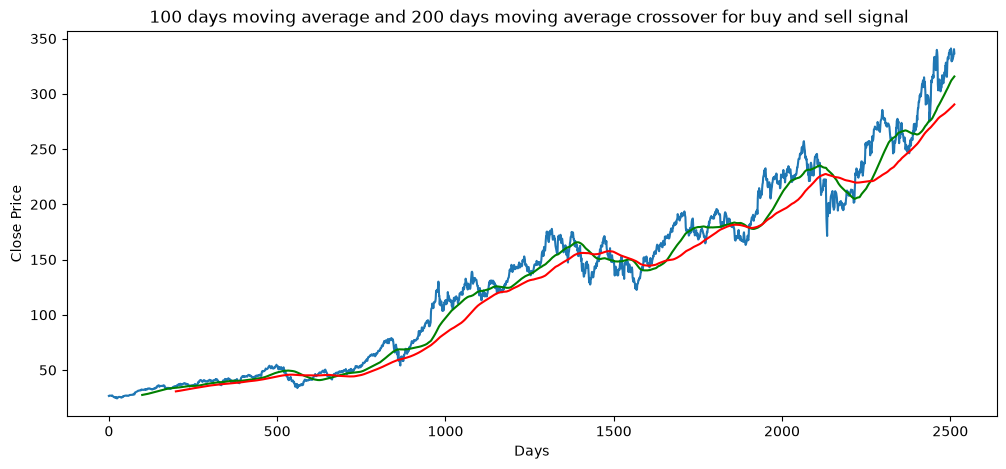

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(df.Close)
plt.plot(df['MA_100'], 'g')
plt.plot(df['MA_200'], 'r')
plt.title('100 days moving average and 200 days moving average crossover for buy and sell signal ')
plt.xlabel("Days")
plt.ylabel("Close Price")

### Calculating % changed in each trading session

In [19]:
df['Percentage_Changed'] = df.Close.pct_change()
df

Price,Date,Close,High,Low,Open,Volume,MA_100,MA_200,Percentage_Changed
Ticker,,AAPL,AAPL,AAPL,AAPL,AAPL,,,
0,2016-10-11,26.596138,27.142696,26.573268,26.916296,256164000,NaN,NaN,NaN
1,2016-10-12,26.833975,26.980335,26.699051,26.836262,150347200,NaN,NaN,0.008943
2,2016-10-13,26.751646,26.856841,26.463502,26.708195,140769600,NaN,NaN,-0.003068
3,2016-10-14,26.900291,27.023782,26.785949,26.957463,142608800,NaN,NaN,0.005556
4,2016-10-17,26.882004,26.948321,26.705915,26.831693,94499600,NaN,NaN,-0.000680
...,...,...,...,...,...,...,...,...,...
2508,2026-10-05,332.890015,336.209991,331.649994,332.820007,34400900,314.162926,289.094099,-0.002397
2509,2026-10-06,333.630005,334.380005,330.619995,332.279999,30449000,314.513101,289.406739,0.002223
2510,2026-10-07,336.670013,338.670013,332.779999,336.959991,34147900,314.900271,289.732833,0.009112


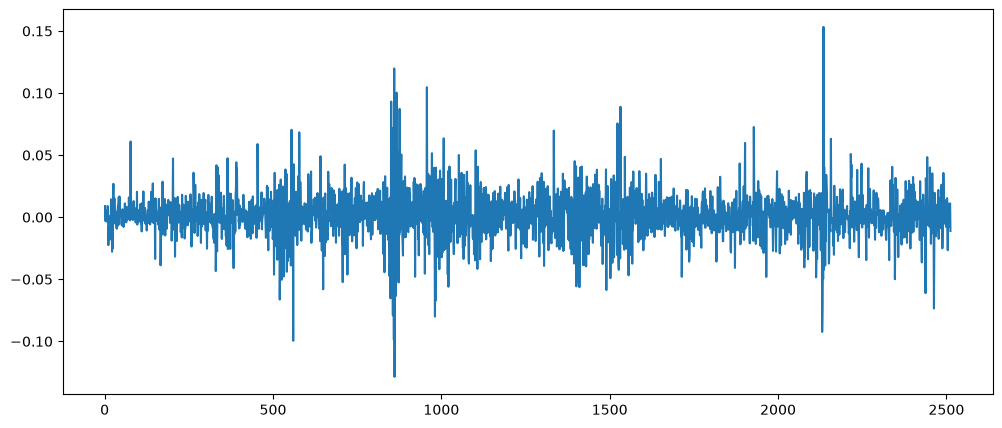

In [20]:
plt.figure(figsize=(12, 5))
plt.plot(df['Percentage_Changed'])

# 4. Data Preprocessing

In [21]:
df.shape


(2513, 9)

In [24]:
# Splitting data into training and testing datasets
data_training = pd.DataFrame(df.Close[0:int(len(df) * 0.7)])
data_testing = pd.DataFrame(df.Close[int(len(df) * 0.7):int(len(df))])
data_training



Ticker,AAPL
0,26.596138
1,26.833975
2,26.751646
3,26.900291
4,26.882004
...,...
1754,171.431366
1755,170.099365
1756,171.342590
1757,172.575897


In [25]:
data_testing

Ticker,AAPL
1759,176.601471
1760,176.009476
1761,177.400650
1762,178.298508
1763,176.463348
...,...
2508,332.890015
2509,333.630005
2510,336.670013
2511,340.420013


In [26]:
# Scaling down the data between 0 and 1

In [27]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))

In [28]:
data_training_array = scaler.fit_transform(data_training)
data_training_array

array([[0.01357406],
       [0.01497914],
       [0.01449276],
       ...,
       [0.86870307],
       [0.87598917],
       [0.89102777]], shape=(1759, 1))

In [29]:
type(data_training_array)

numpy.ndarray

### 5. Sequence Creation

In [33]:
x_train = []
y_train = []

for i in range(100, data_training_array.shape[0]):
    x_train.append(data_training_array[i-100: i])
    y_train .append(data_training_array[i, 0])

x_train, y_train = np.array(x_train), np.array(y_train)
x_train

array([[[0.01357406],
        [0.01497914],
        [0.01449276],
        ...,
        [0.04597028],
        [0.04708855],
        [0.04648848]],

       [[0.01497914],
        [0.01449276],
        [0.01537093],
        ...,
        [0.04708855],
        [0.04648848],
        [0.04673397]],

       [[0.01449276],
        [0.01537093],
        [0.01526289],
        ...,
        [0.04648848],
        [0.04673397],
        [0.04602477]],

       ...,

       [[0.86646467],
        [0.86099302],
        [0.85808222],
        ...,
        [0.85442205],
        [0.86922754],
        [0.86135838]],

       [[0.86099302],
        [0.85808222],
        [0.85808222],
        ...,
        [0.86922754],
        [0.86135838],
        [0.86870307]],

       [[0.85808222],
        [0.85808222],
        [0.86169138],
        ...,
        [0.86135838],
        [0.86870307],
        [0.87598917]]], shape=(1659, 100, 1))

In [34]:
x_train.ndim

3

In [35]:
y_train.ndim

1

In [36]:
y_train

array([0.04673397, 0.04602477, 0.04558833, ..., 0.86870307, 0.87598917,
       0.89102777], shape=(1659,))

### 6. Model Building

In [41]:
!pip install tensorflow

In [42]:
import tensorflow as tf
print(tf.__version__)

2.22.0-rc0


In [43]:
# ML Model
from keras.models import Sequential
from keras.layers import Dense, LSTM, Input


In [44]:
model = Sequential()
model.add(Input(shape=(100, 1)))
model.add(LSTM(units=128, activation='tanh', return_sequences=True))
model.add(LSTM(units=64))
model.add(Dense(25))
model.add(Dense(1))

### 7. Model Training

In [45]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(x_train, y_train, epochs=50)

Epoch 1/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 11s 153ms/step - loss: 0.0134
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - loss: 7.5612e-04
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - loss: 7.1594e-04
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - loss: 6.7156e-04
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - loss: 6.2777e-04
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - loss: 6.0155e-04
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - loss: 5.6593e-04
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - loss: 5.4604e-04
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 99ms/step - loss: 5.4106e-04
Epoch 10/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - loss: 5.1411e-04
Epoch 11/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - loss: 4.7582e-04
Epoch 12/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - loss: 4.4602e-04
Epoch 13/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - loss: 4.2828e-04
Epoch 14/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - loss: 4.1627e-04
Epoch 15/50
52

In [47]:
model.save('pre_trained_model_for_stock_prediction.keras')

# 8. Prepare Test Data

In [48]:
data_testing

Ticker,AAPL
1759,176.601471
1760,176.009476
1761,177.400650
1762,178.298508
1763,176.463348
...,...
2508,332.890015
2509,333.630005
2510,336.670013
2511,340.420013


In [49]:
data_training.tail()

Ticker,AAPL
1754,171.431366
1755,170.099365
1756,171.342590
1757,172.575897
1758,175.121460


In [50]:
past_100_days = data_training.tail(100)

In [51]:
past_100_days

Ticker,AAPL
1659,169.544815
1660,170.155731
1661,172.481079
1662,172.589493
1663,171.643570
...,...
1754,171.431366
1755,170.099365
1756,171.342590
1757,172.575897


In [52]:
final_df = pd.concat([past_100_days, data_testing], ignore_index=True)
final_df


Ticker,AAPL
0,169.544815
1,170.155731
2,172.481079
3,172.589493
4,171.643570
...,...
849,332.890015
850,333.630005
851,336.670013
852,340.420013


In [53]:
input_data = scaler.fit_transform(final_df)


In [55]:
x_test = []
y_test = []
for i in range(100, input_data.shape[0]):
    x_test.append(input_data[i-100: i])
    y_test.append(input_data[i, 0])

In [56]:
x_test, y_test = np.array(x_test), np.array(y_test)

# 9. Making Predictions

In [57]:
y_predicted = model.predict(x_test)

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step


In [58]:
y_predicted = scaler.inverse_transform(y_predicted.reshape(-1,1)).flatten()
y_test = scaler.inverse_transform(y_test.reshape(-1,1)).flatten()

In [59]:
y_predicted

array([172.82071, 174.40523, 175.45493, 176.44395, 177.38972, 177.50446,
       177.30617, 176.62332, 175.63295, 174.73409, 173.41655, 172.37976,
       171.82782, 170.96132, 169.1562 , 167.87137, 167.59563, 167.84164,
       169.01575, 171.16144, 172.81346, 174.56996, 176.61092, 178.46805,
       179.57675, 181.4156 , 182.40498, 183.67685, 184.80449, 186.08394,
       186.98976, 188.08083, 188.59578, 189.01404, 188.82233, 188.4789 ,
       188.40332, 188.0879 , 188.00795, 188.43524, 188.27397, 189.32104,
       189.97913, 190.9804 , 192.22186, 192.24559, 192.46983, 193.76424,
       194.94318, 195.5075 , 195.13148, 195.01324, 194.25354, 193.55568,
       192.74365, 192.00264, 191.56868, 191.50757, 191.22061, 188.73555,
       186.10986, 183.56232, 181.60861, 181.68819, 182.2065 , 183.03163,
       183.51794, 183.86005, 183.34479, 182.45894, 183.53949, 185.772  ,
       188.4209 , 190.78543, 192.05957, 192.49123, 191.94064, 191.08437,
       189.21399, 186.57057, 185.36307, 184.59488, 

In [60]:
y_test

array([176.60147095, 176.00947571, 177.40065002, 178.29850769,
       176.46334839, 176.33505249, 174.78601074, 173.49349976,
       173.11856079, 170.57299805, 170.69139099, 171.12550354,
       168.8167572 , 164.66291809, 165.97517395, 168.01754761,
       168.49113464, 171.64842224, 175.20036316, 174.29266357,
       176.83825684, 179.39369202, 180.4493866 , 179.97583008,
       184.15486145, 182.5741272 , 185.18234253, 185.74545288,
       187.42500305, 187.40522766, 189.14401245, 188.34381104,
       189.00572205, 187.68185425, 187.50401306, 188.10665894,
       187.08908081, 187.66209412, 188.93655396, 187.14834595,
       191.09028625, 190.00354004, 191.93006897, 193.35273743,
       190.85316467, 192.36477661, 195.5756073 , 195.72381592,
       195.19032288, 193.5305481 , 194.56791687, 192.48330688,
       192.33512878, 191.26812744, 190.7247467 , 190.8235321 ,
       191.24835205, 190.21102905, 183.40402222, 182.03077698,
       179.71893311, 178.99771118, 183.32496643, 182.91

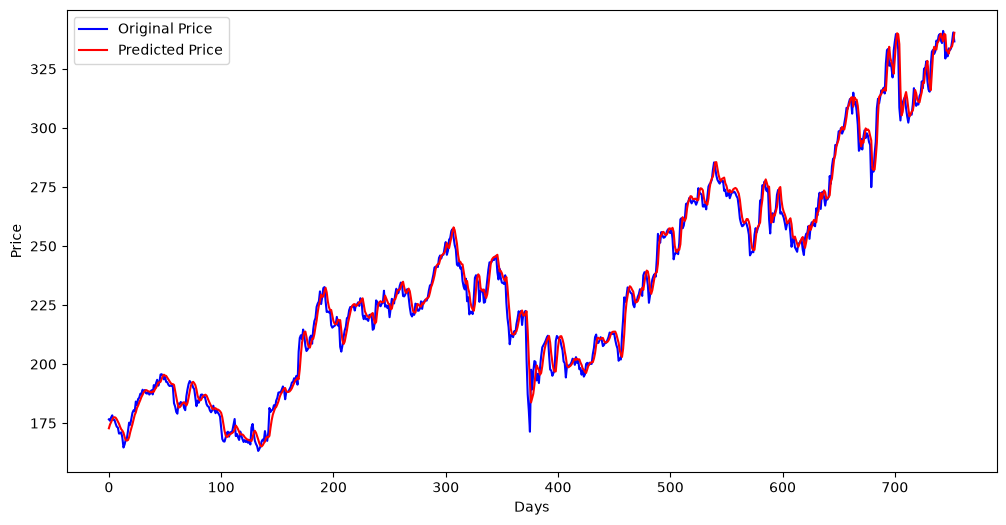

In [63]:
plt.figure(figsize=(12, 6))
plt.plot(y_test, 'b', label='Original Price')
plt.plot(y_predicted, 'r', label='Predicted Price')
plt.xlabel('Days')
plt.ylabel('Price')
plt.legend()

(200.0, 300.0)

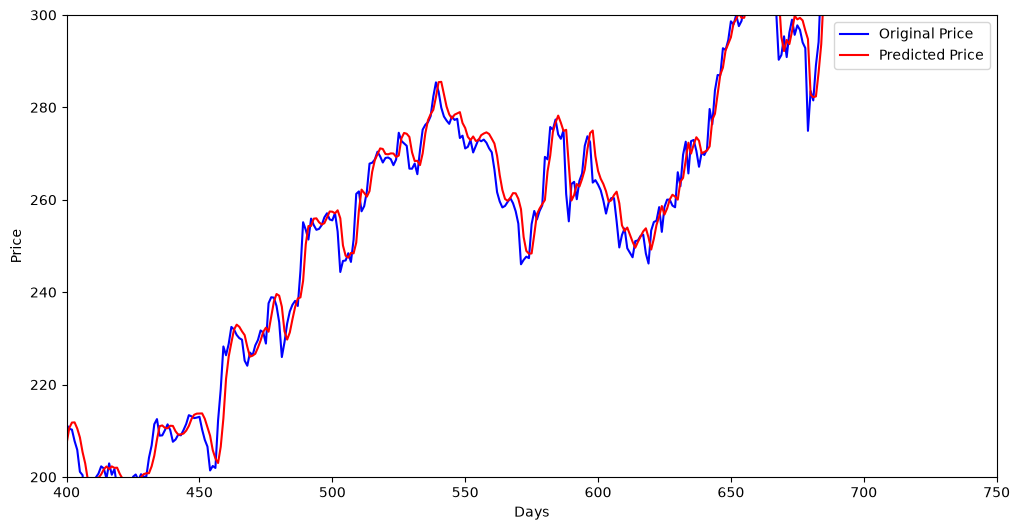

In [62]:
plt.figure(figsize=(12, 6))
plt.plot(y_test, 'b', label='Original Price')
plt.plot(y_predicted, 'r', label='Predicted Price')
plt.xlabel('Days')
plt.ylabel('Price')
plt.legend()
plt.xlim(400, 750)
plt.ylim(200, 300)

# 10. Model Evaluation

In [70]:
# Mean Squared Error(MSE)
from sklearn.metrics import mean_squared_error, r2_score


In [65]:
mse = mean_squared_error(y_test, y_predicted)

In [67]:
print(f"Mean Squared Error (MSE): {mse}")

Mean Squared Error (MSE): 21.967042095016748


In [68]:
# Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)


In [69]:
print(f"Root Mean Squared Error (RMSE): {rmse}")

Root Mean Squared Error (RMSE): 4.686901118544827


In [71]:
# R-Squared
r2 = r2_score(y_test, y_predicted)
print(f"R-Squared: {r2}")

R-Squared: 0.9889495401963754
